# Fourier Transform for Data Science  

Signals, sound, voltage, vibration, images, time series, often look messy.  
But they can be built from simpler **sinusoidal waves** (smooth, repeating waves like sine or cosine).

A sinusoid has three properties:

- **Frequency** is how often it repeats. Sound is measured in Hz (cycles per second). Images use *spatial frequency* (how quickly brightness changes, in inverse length).
- **Amplitude** is how strong or tall the wave is. In the frequency domain, the amplitude spectrum tells us how much of each frequency is present.
- **Phase** is the timing or offset of the wave. Two waves can have the same frequency and amplitude but be shifted in time. Phase captures that shift.

**Superposition:** When waves overlap, they add together.  
- If a peak lines up with a peak, they **reinforce**, the result is bigger.  
- If a peak lines up with a trough, they **cancel**, the result is smaller (or even zero).  
Think of two people pushing a swing: push together and it goes higher; push opposite and it barely moves.

---

## What Is the Fourier Transform?

### Fourier Series

The Fourier series represents a periodic signal as a sum of sinusoids. For a periodic signal $x_T(t)$, the Fourier coefficients are calculated as:

$$
a_k = \frac{1}{T}\int_{-T/2}^{T/2} x_T(t)e^{-j\frac{2\pi}{T}kt}\,dt
$$

These coefficients describe how much each harmonic contributes to the original signal. If the period of the signal doubles, the number of harmonics in a given frequency interval also doubles. As the period approaches infinity, the discrete harmonic amplitudes become a continuum, and the Fourier series becomes the Fourier transform.

In simpler terms, the Fourier series says that a repeating signal can be built from sine and cosine waves. The coefficients determine the shape of the reconstructed signal.


### Fourier Transform

The Fourier transform generalizes the Fourier series to aperiodic signals. The forward Fourier transform converts a time-domain signal into a frequency-domain representation:

$$
X(j\omega) = \int_{-\infty}^{\infty} x(t)e^{-j\omega t}\,dt
$$

The inverse Fourier transform converts the frequency-domain representation back into the original time-domain signal:

$$
x(t) = \frac{1}{2\pi}\int_{-\infty}^{\infty} X(j\omega)e^{j\omega t}\,d\omega
$$

These equations are called the analysis and synthesis equations, respectively.

In the notation used in the physics booklet, the one-dimensional continuous Fourier transform is written as:

$$
F(u) = \int_{-\infty}^{\infty} f(x)\exp(-i2\pi ux)\,dx
$$

and its inverse is:

$$
f(x) = \int_{-\infty}^{\infty} F(u)\exp(i2\pi ux)\,du
$$

The difference between these notations is mainly where the factor of $2\pi$ appears.

The Fourier transform moves a signal from the time domain to the frequency domain, while the inverse Fourier transform moves it back. The transform is also closely related to the Laplace transform. If the Laplace transform exists and its region of convergence includes the $j\omega$ axis, then the Fourier transform is the Laplace transform evaluated on that axis:

$$
X(j\omega) = X(s)\big|_{s=j\omega}
$$


---

### Winding-Machine Intuition

The Fourier transform formula can be understood visually. Imagine wrapping the signal around a circle at some test frequency. When the test frequency matches a frequency inside the signal, the center of mass of the wrapped signal moves far from the origin. Plotting that center-of-mass position for many test frequencies reveals peaks at the frequencies contained in the signal.

![Winding-machine intuition](winding_machine_intuition.png)

*Figure: The winding-machine intuition. The signal (top) is wrapped around a circle at a test frequency (bottom left). The x-coordinate of the center of mass (bottom right) peaks when the test frequency matches a frequency in the signal. Source: 3Blue1Brown, "But what is the Fourier Transform?"*

---

## Properties of the Fourier Transform

### Linearity

If you add two signals together and then take the Fourier transform, you get the same result as taking the transform of each signal separately and then adding those results. In other words, the Fourier transform of a sum is the sum of the Fourier transforms.

This means we can break a complicated signal into simpler pieces, transform each piece, and then combine the answers. It also means that scaling a signal scales its transform by the same amount.

$$
a x_1(t) + b x_2(t) \;\leftrightarrow\; a X_1(j\omega) + b X_2(j\omega)
$$

### Time Shifting

If you delay a signal by a time $t_0$, its frequency content does not change. Only the phase (timing) of each frequency component changes. The magnitude of the Fourier transform stays the same.

This is why a delayed echo sounds like the same sound, just later. The frequencies are the same, but the timing is shifted.

$$
x(t - t_0) \;\leftrightarrow\; e^{-j\omega t_0} X(j\omega)
$$

### Time Scaling

If you stretch a signal in time (play it slower), its frequencies become compressed (lower). If you compress a signal in time (play it faster), its frequencies become higher. The amplitude also changes so that the total area under the curve is preserved.

This is why slowing down a sound makes it deeper, and speeding it up makes it higher-pitched.

$$
x(at) \;\leftrightarrow\; \frac{1}{|a|} X\!\left(\frac{j\omega}{a}\right)
$$

### Differentiation

Taking the derivative of a signal in the time domain is the same as multiplying its Fourier transform by $j\omega$ in the frequency domain.

This turns calculus (derivatives) into simple algebra (multiplication), which is easier for computers and for solving differential equations.

$$
\frac{d x(t)}{dt} \;\leftrightarrow\; j\omega X(j\omega)
$$

### Convolution

Convolution is a mathematical way to combine two signals. For example, applying a filter to a sound is a convolution. The convolution theorem says that convolution in the time domain equals multiplication in the frequency domain.

This means filtering a signal is much faster if you transform it, multiply by the filter's frequency response, and then transform back. This is the basis of almost all audio and image filtering.

$$
x_1(t) * x_2(t) \;\leftrightarrow\; X_1(j\omega) X_2(j\omega)
$$


### Parseval's Theorem

The total energy of a signal is the same whether you measure it in the time domain or in the frequency domain.

This means you can analyze a signal's power by looking at its spectrum, and you will not lose or gain energy in the process.

$$
\int |f(x)|^2\,dx = \int |F(u)|^2\,du
$$


### Symmetry for Real Signals

If the original signal is real-valued (like a sound recording), its Fourier transform has a special symmetry. The real part is symmetric, the imaginary part is anti-symmetric, and the power spectrum is symmetric.

This symmetry means computers only need to calculate half of the frequency values, which saves time and memory. Libraries such as cuFFT use this to speed up real-to-complex transforms.

---

## From Continuous Signals to Digital Data

Real-world signals such as sound, temperature, and voltage are continuous. They have a value at every instant. But computers can only store a finite list of numbers. So we sample the signal: we measure its value at regular intervals. For example, audio is often sampled 44,100 times per second.

This gives us a finite sequence of numbers. To find the frequencies in this sequence, we use the Discrete Fourier Transform, or DFT.

The DFT takes a finite list of samples and produces a same-length list of frequency coefficients. This is called the forward DFT. Changing the sign of the exponent gives the inverse DFT, which turns the frequency coefficients back into the original samples.

The output of the DFT is a list of complex numbers, written as $a + ib$. Using Euler's formula, we can separate these into real and imaginary parts, which correspond to cosine and sine components.

The DFT is what computers actually calculate. The Fast Fourier Transform (FFT) is a fast algorithm for computing the same DFT result. When you use `np.fft.fft()` in Python, you are computing the DFT efficiently.

## Fast Fourier Transform

The FFT is a divide-and-conquer algorithm. This means it breaks a large problem into smaller problems, solves each smaller problem, and then combines the results. It recursively divides a large DFT into smaller DFTs, which reduces the amount of computation dramatically.

To understand the difference in speed, we can compare the number of operations. The direct DFT requires approximately $2N^2$ operations, where $N$ is the number of samples. The FFT reduces this to approximately $2N\log N$ operations. For small $N$, the difference is small, but for large $N$, the difference is enormous. For example, if $N = 1{,}000{,}000$, the direct DFT needs about $2 \times 10^{12}$ operations, while the FFT needs about $2 \times 10^6 \times 20 = 4 \times 10^7$ operations, which is tens of thousands of times fewer.

The FFT was formalized by Cooley and Tukey in 1965. It reduced the number of arithmetic operations from $O(N^2)$ to $O(N\log N)$, which made real-time spectral analysis practical for the first time.

The cuFFT library uses the Cooley-Tukey algorithm and implements building blocks such as radix-2, radix-3, radix-5, and radix-7. These radices refer to the small DFT sizes that are combined to build larger transforms. When a transform length cannot be decomposed into powers of primes from 2 to 127, cuFFT uses Bluestein's algorithm, which is a different method for handling arbitrary lengths.

---

## First Demonstration: Two Hidden Frequencies

In the demonstration, I create a signal made from two sine waves:

- A strong 50 Hz wave with amplitude 1.
- A weaker 80 Hz wave with amplitude 0.5.

When we plot the time-domain signal, the two components are mixed together, and the waveform looks complicated. After applying the FFT, we should see two peaks in the frequency domain: a taller peak at 50 Hz and a shorter peak at 80 Hz. A large magnitude at a frequency means that this frequency contributes strongly to the signal.

The code below creates this signal, computes its FFT, and plots both the time-domain signal and the frequency-domain spectrum. The comments explain each step.

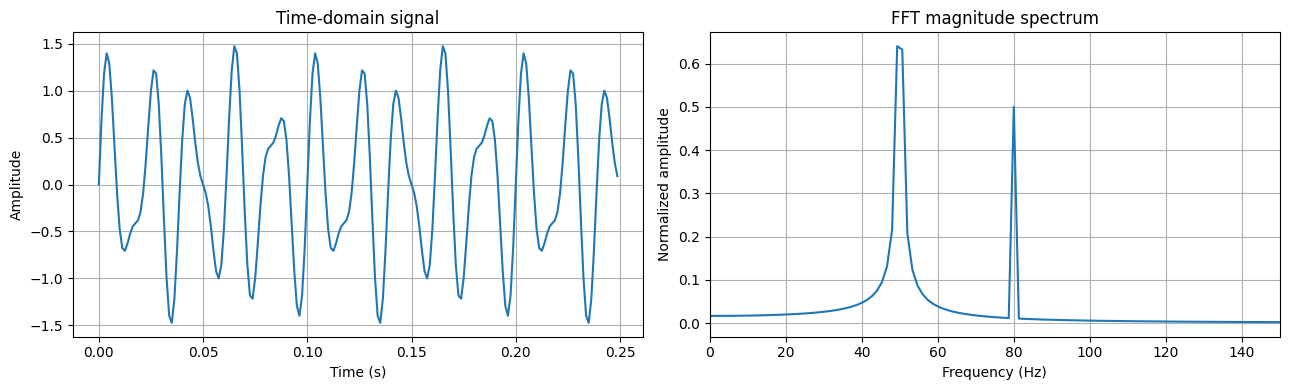

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 600
T = 1.0 / 800.0

x = np.arange(N) * T

y = (
    np.sin(50.0 * 2.0 * np.pi * x)
    + 0.5 * np.sin(80.0 * 2.0 * np.pi * x)
)

yf = np.fft.fft(y)

xf = np.fft.fftfreq(N, T)[:N // 2]

amplitude = 2.0 / N * np.abs(yf[:N // 2])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(x[:200], y[:200])
ax[0].set_title("Time-domain signal")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True)

ax[1].plot(xf, amplitude)
ax[1].set_title("FFT magnitude spectrum")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Normalized amplitude")
ax[1].set_xlim(0, 150)
ax[1].grid(True)

plt.tight_layout()
plt.show()

## Data Science Use 1: Feature Extraction

In data science, the Fourier transform is often used as a preprocessing and feature-extraction tool.

A raw time-series signal may contain thousands of samples. However, if the signal is periodic, its important structure may be captured by only a few frequency-domain values. This can simplify the dataset considerably. Instead of giving a machine-learning model thousands of raw sensor readings, we can give it features such as:

- Dominant frequency
- Spectral power
- Phase information
- Energy in low, medium, and high frequency bands

The Fourier domain can also provide translation invariance. If two signals are shifted in time, their frequency-domain representations may be less affected by that shift. This means that even if there are lags between signals, those lags do not change how the signals appear in the frequency domain.

---

## Data Science Use 2: Noise Filtering

Fourier analysis is widely used for filtering. The basic idea is:

1. Transform the noisy signal into the frequency domain.
2. Identify unwanted frequency components.
3. Remove or reduce those components.
4. Apply the inverse Fourier transform to reconstruct a cleaner signal.

For example: “Let's imagine that you have a voice recording, but there is an annoying ringing sound in it that you want to get rid of. Remember that this signal will be received as a plot of intensity over time. Ideally, we would like to think of this signal in terms of frequencies, so we need to take the Fourier transform of the signal to find the most prominent frequencies. From there, we will see the annoying high-pitched ringing sound as a spike on the far right of the plot.” Then: “If we remove the spike by smooshing it out on the frequency plot, we will have a sound that is almost identical to the recording, but without the ringing. To go back to the original signal, we need to use another concept known as the inverse Fourier transform, and after applying this operation, we have effectively removed the high-pitched ringing noise from the signal”.

Fourier methods are also used in image filtering, image reconstruction, edge detection, and image compression. Fourier transform is also widely used in image analysis eg. edge detection, image filtering, image reconstruction, and image compression.”

The code below demonstrates the filtering process. It creates a clean 40 Hz signal, adds unwanted 300 Hz noise, then removes frequencies above 100 Hz using the FFT and inverse FFT.

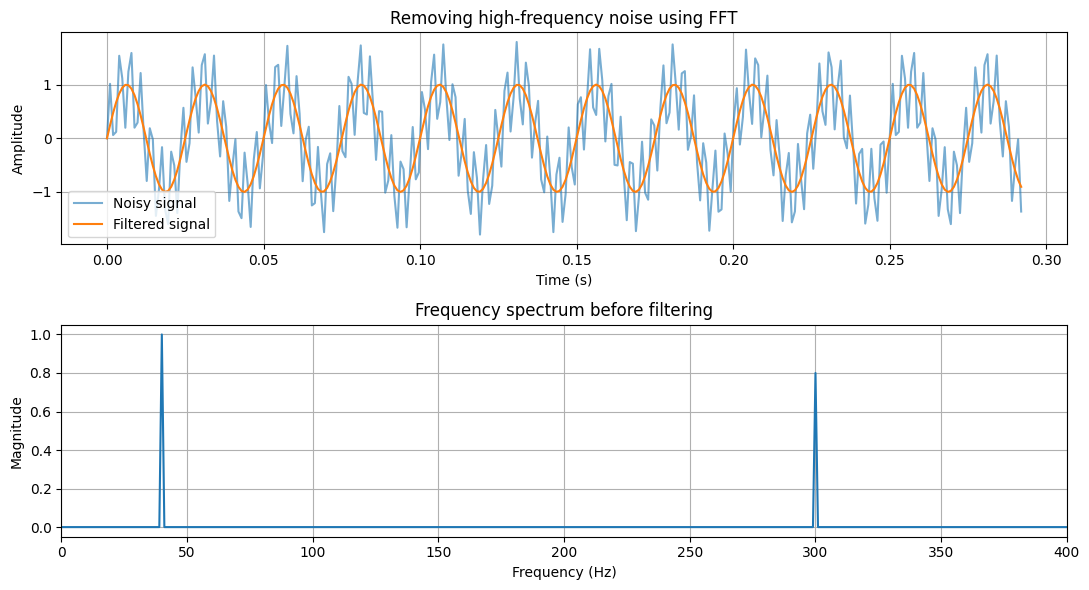

In [1]:

import numpy as np
import matplotlib.pyplot as plt

N = 1024
T = 1 / 1024
t = np.arange(N) * T

signal = np.sin(2 * np.pi * 40 * t)

noise = 0.8 * np.sin(2 * np.pi * 300 * t)

y = signal + noise

Y = np.fft.fft(y)
freqs = np.fft.fftfreq(N, T)

Y_filtered = Y.copy()
Y_filtered[np.abs(freqs) > 100] = 0

y_clean = np.fft.ifft(Y_filtered).real

fig, ax = plt.subplots(2, 1, figsize=(11, 6))

ax[0].plot(t[:300], y[:300], alpha=0.6, label="Noisy signal")
ax[0].plot(t[:300], y_clean[:300], label="Filtered signal")
ax[0].set_title("Removing high-frequency noise using FFT")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(freqs[:N // 2], 2 / N * np.abs(Y[:N // 2]))
ax[1].set_title("Frequency spectrum before filtering")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Magnitude")
ax[1].set_xlim(0, 400)
ax[1].grid(True)

plt.tight_layout()
plt.show()

---

## Data Science Use 3: Audio Processing

Sound is a pressure wave that travels through air or another material. At any point, the pressure rises and falls in a regular pattern over time. That is why sine and cosine waves describe sound. The Fourier transform and its fast version, the FFT, are used for audio processing, speech recognition, and noise cancellation. The FFT is also used in digital recording, sampling, additive synthesis (building sounds by adding waves), and pitch correction software. Fast cosine and sine transforms are used in JPEG and MP3 encoding and decoding.

The regular Fourier transform shows which frequencies are in a signal, but not when they occur. The Short-Time Fourier Transform (STFT) solves this by computing the spectrum in small, overlapping windows of the signal. This produces a spectrogram, a picture that shows both time and frequency. There is a tradeoff: a long window gives good frequency detail but poor time detail; a short window does the opposite. Wavelet transforms handle this tradeoff by using basis functions that are localized in both time and frequency, adapting their resolution to the signal's content.

---

## Data Science Use 4: Machine Learning and CNNs

The Fourier transform is a linear operation. That means it cannot capture curved or nonlinear relationships by itself. To handle nonlinearity, machine learning models combine convolutions with activation functions.

Using the convolution theorem from the properties section, we can replace convolution with multiplication in the frequency domain. This is the main way the Fourier transform is used in machine learning and deep learning.

In Convolutional Neural Networks (CNNs), about 90% of the computations are convolutions. A convolution is a mathematical operation that slides one signal over another, multiplying and adding as it goes. One way to reduce the cost of these computations is to use the Fast Fourier Transform (FFT). Instead of computing the convolution directly, the input and the filter are converted into the frequency domain using the FFT. Then the multiplication is done in the frequency domain. Finally, the result is converted back into the time domain using the Inverse FFT (IFFT).

Other than CNNs, the FFT has many other uses in machine learning and scientific computing. Other FFT applications relevant to machine learning include fast multiplication of large numbers and polynomials, efficient matrix-vector multiplication for special kinds of matrices, filtering algorithms, fast cosine and sine transforms, fast Chebyshev approximation, solving difference equations, and computing isotopic distributions.


---

## Sources

- https://www2.ph.ed.ac.uk/~wjh/teaching/Fourier/documents/booklet.pdf
- https://technav.ieee.org/topic/fourier-transforms/
- https://www.kdnuggets.com/2020/02/fourier-transformation-data-scientist.html
- https://www.3blue1brown.com/lessons/fourier-transforms/
- https://ocw.mit.edu/courses/6-003-signals-and-systems-fall-2011/resources/mit6_003f11_lec16/